In [1]:
import numpy as np
import matplotlib.pyplot as plt
import keras
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Flatten, Dense
%matplotlib inline

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()
x_train.shape, y_train.shape, " ", x_test.shape, y_test.shape

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


((60000, 28, 28), (60000,), ' ', (10000, 28, 28), (10000,))

In [3]:
x_train[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,
          0,   0,  13,  73,   0,   0,   1,   4,   0,   0,   0,   0,   1,
          1,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
          0,  36, 136, 127,  62,  54,   0,   0,   0,   1,   3,   4,   0,
          0,   3],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   6,
          0, 102, 204, 176, 134, 144, 123,  23,   0,   0,   0,   0,  12,
         10,   0],
       [  

In [4]:
class_labels = ["Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker"]
class_labels

['Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker']

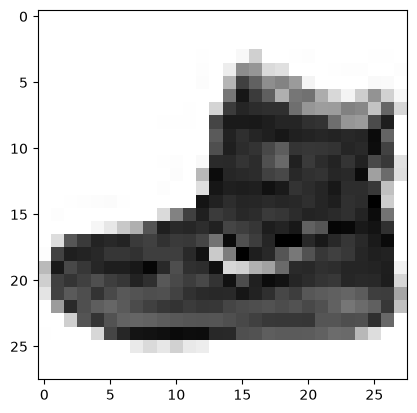

In [5]:
plt.imshow(x_train[0], cmap="Greys")

In [6]:
x_train.shape

(60000, 28, 28)

IndexError: list index out of range

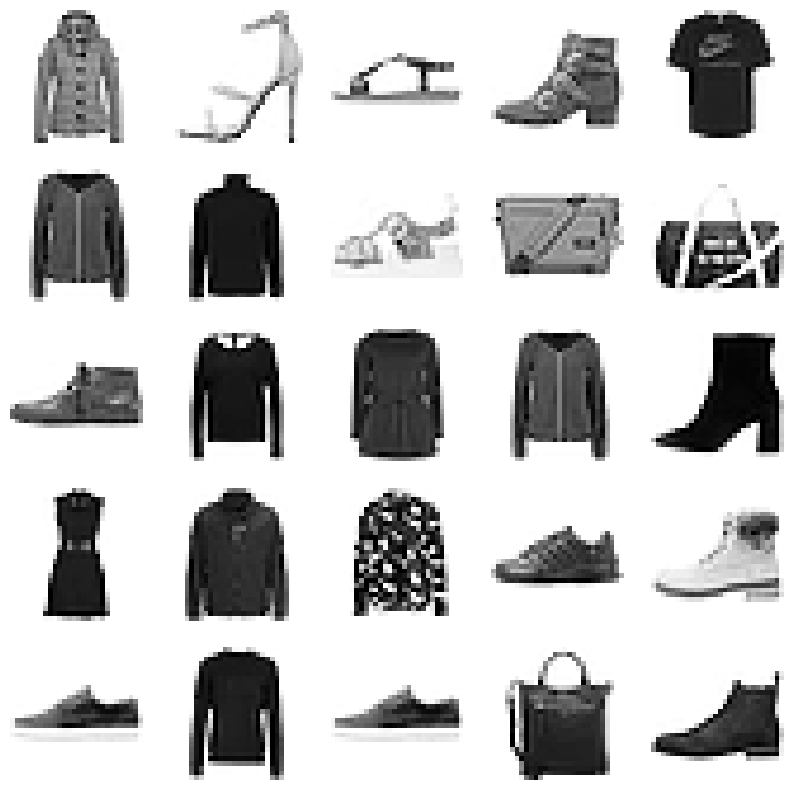

In [7]:
plt.figure(figsize = (10, 10))
j = 1
for i in np.random.randint(0, 1000, 25):
    plt.subplot(5, 5, j)
    j += 1
    plt.imshow(x_train[i], cmap = "Greys")
    plt.axis('off')
plt.title('{} / {}'.format(class_labels[y_train[i]], y_train[i]))

In [8]:
x_train.ndim

3

In [9]:
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
x_train.ndim

4

In [10]:
x_train = x_train/255
x_test = x_test/255

In [11]:
from sklearn.model_selection import train_test_split
x_train, x_validation, y_train, y_validation = train_test_split(x_train, y_train)
x_train.shape, y_train.shape, x_validation.shape, y_validation.shape

((45000, 28, 28, 1), (45000,), (15000, 28, 28, 1), (15000,))

In [12]:
cnn = keras.models.Sequential([
    tf.keras.layers.Conv2D(filters = 32, kernel_size = 3, strides = (1, 1), 
                           padding = 'valid', activation = 'relu', input_shape = (28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(filters = 64, kernel_size = 3, strides = (2, 2), 
                           padding = 'same', activation = 'relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation = 'relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(256, activation = 'relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(128, activation = 'relu'),
    tf.keras.layers.Dense(10, activation = 'softmax'),
])

/Users/soni/Developer/learning-in-public/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [13]:
cnn.compile(optimizer = 'adam', loss = 'sparse_categorical_crossentropy',
           metrics = ['accuracy'])
cnn.fit(x_train, y_train, epochs = 20, batch_size = 16, verbose = 1,
       validation_data = (x_validation, y_validation))

Epoch 1/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.7840 - loss: 0.5740 - val_accuracy: 0.8554 - val_loss: 0.4021
Epoch 2/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8596 - loss: 0.3805 - val_accuracy: 0.8740 - val_loss: 0.3419
Epoch 3/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8806 - loss: 0.3294 - val_accuracy: 0.8823 - val_loss: 0.3270
Epoch 4/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8898 - loss: 0.3021 - val_accuracy: 0.8861 - val_loss: 0.3061
Epoch 5/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.8949 - loss: 0.2836 - val_accuracy: 0.8925 - val_loss: 0.3003
Epoch 6/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9028 - loss: 0.2634 - val_accuracy: 0.8859 - val_loss: 0.3076
Epoch 7/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9080 - loss: 0.2495 - val_accuracy: 0.8968 - val_loss: 0.2932
Epoch 8/20
2813/2813 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9112 - loss: 0.2383 - 

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8973 - loss: 0.3258  


IndexError: list index out of range

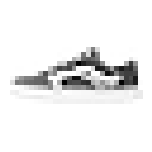

In [14]:
y_pred = cnn.predict(x_test)

cnn.evaluate(x_test, y_test)


plt.figure(figsize = (10, 10))
j = 1
for i in np.random.randint(0, 1000, 25):
    plt.subplot(5, 5, j)
j += 1
plt.imshow(x_train[i], cmap = 'Greys')
plt.axis('off')
plt.title('{} / {}'.format(class_labels[y_train[i]], y_train[i]))